In [31]:
#install openCV-open computer vision library
#use to anlysis and process images and vedioes using computer
!pip install opencv-python-headless
#Color Detection System

In [32]:
#import libraries
import cv2
import numpy as np #work with arrays in this pixel values
import matplotlib.pyplot as plt #visualization in this display images
from google.colab import files #to upload image from computer

Saving images (6).jpeg to images (6) (1).jpeg


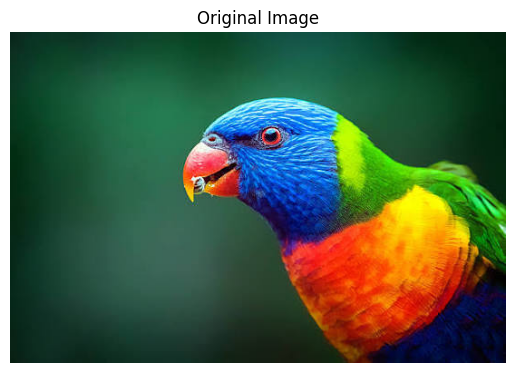

In [34]:
uploaded = files.upload()
#files.upload()-select file from computer and open
#uploaded-variable for store uploaded image details

filename = next(iter(uploaded))
#iterate upload files
#next()-get first file name

image = cv2.imread(filename)
#read image file using openCV

image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
#change color format
#normally openCV read images using BGR(blue,green,red)
#for Matplotlib it convert to RGB format

plt.imshow(image)
plt.title("Original Image")
plt.axis("off") #hide axis
plt.show()

In [35]:
#files.upload() — get image from computer
#cv2.imread() — read image
#cv2.cvtColor() — change colour format
#plt.imshow() — image display
#plt.show() — output display

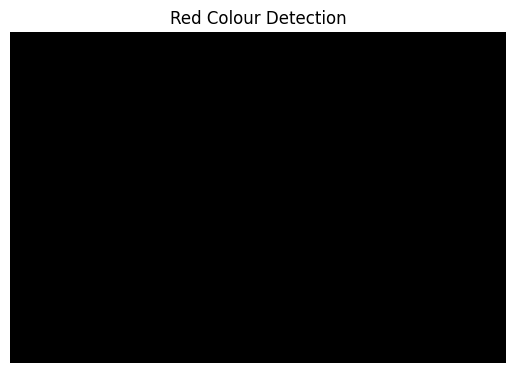

In [24]:
# Convert image to HSV
#from RGB to HSV(hue,saturation,value)
#easy to identify color using HSV
hsv = cv2.cvtColor(image, cv2.COLOR_RGB2HSV)

# Define red colour range
lower_red1 = np.array([0, 100, 100])
upper_red1 = np.array([10, 255, 255])

lower_red2 = np.array([170, 100, 100])
upper_red2 = np.array([179, 255, 255])

# Create masks
mask1 = cv2.inRange(hsv, lower_red1, upper_red1)
mask2 = cv2.inRange(hsv, lower_red2, upper_red2)

red_mask = cv2.bitwise_or(mask1, mask2)

# Display detected red areas
plt.imshow(red_mask, cmap="gray")
plt.title("Red Colour Detection")
plt.axis("off")
plt.show()

Red


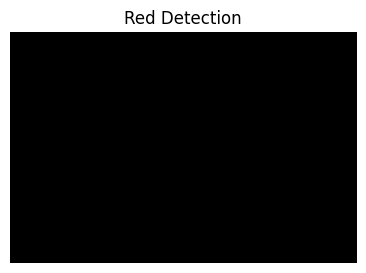

Green


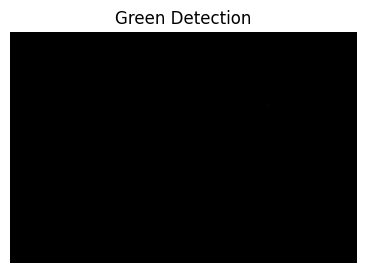

Blue


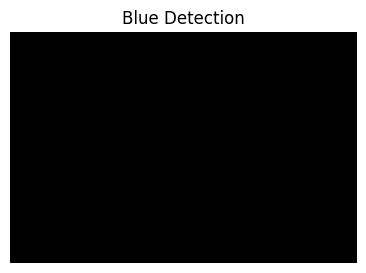

Yellow


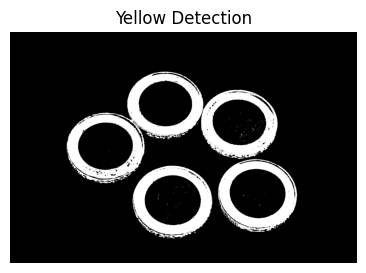

In [25]:
hsv = cv2.cvtColor(image, cv2.COLOR_RGB2HSV)

colour_ranges = {
    "Red": [
        ([0, 100, 100], [10, 255, 255]),
        ([170, 100, 100], [179, 255, 255])
    ],
    "Green": [
        ([35, 60, 40], [85, 255, 255])
    ],
    "Blue": [
        ([90, 60, 40], [135, 255, 255])
    ],
    "Yellow": [
        ([20, 80, 80], [35, 255, 255])
    ]
}

for colour, ranges in colour_ranges.items():
    mask = np.zeros(hsv.shape[:2], dtype=np.uint8)

    for lower, upper in ranges:
        mask_range = cv2.inRange(
            hsv,
            np.array(lower),
            np.array(upper)
        )
        mask = cv2.bitwise_or(mask, mask_range)

    print(colour)

    plt.figure(figsize=(5, 3))
    plt.imshow(mask, cmap="gray")
    plt.title(colour + " Detection")
    plt.axis("off")
    plt.show()

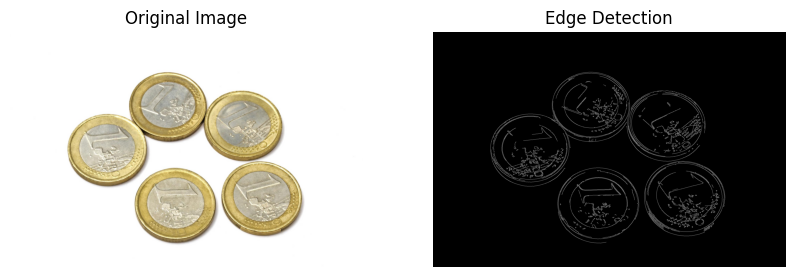

In [26]:
# Convert image to grayscale
gray = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)

# Reduce noise
blurred = cv2.GaussianBlur(gray, (5, 5), 0)

# Detect edges
edges = cv2.Canny(blurred, 100, 200)

# Display result
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(image)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(edges, cmap="gray")
plt.title("Edge Detection")
plt.axis("off")

plt.show()

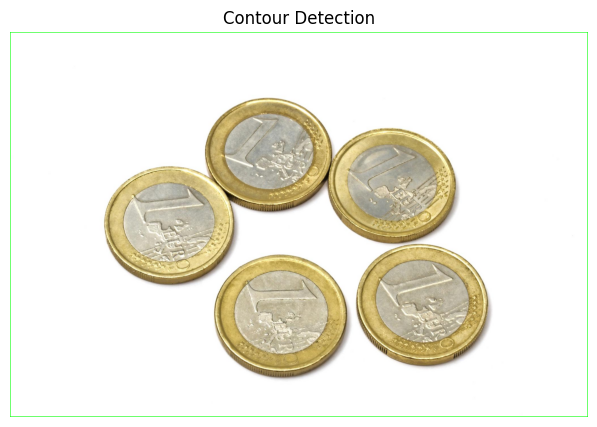

Number of contours: 1


In [27]:
# Convert image to grayscale
gray = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)

# Apply thresholding
_, binary = cv2.threshold(
    gray, 127, 255, cv2.THRESH_BINARY
)

# Find contours
contours, hierarchy = cv2.findContours(
    binary,
    cv2.RETR_EXTERNAL,
    cv2.CHAIN_APPROX_SIMPLE
)

# Copy original image
result = image.copy()

# Draw contours
cv2.drawContours(result, contours, -1, (0, 255, 0), 2)

# Display result
plt.figure(figsize=(10, 5))
plt.imshow(result)
plt.title("Contour Detection")
plt.axis("off")
plt.show()

print("Number of contours:", len(contours))

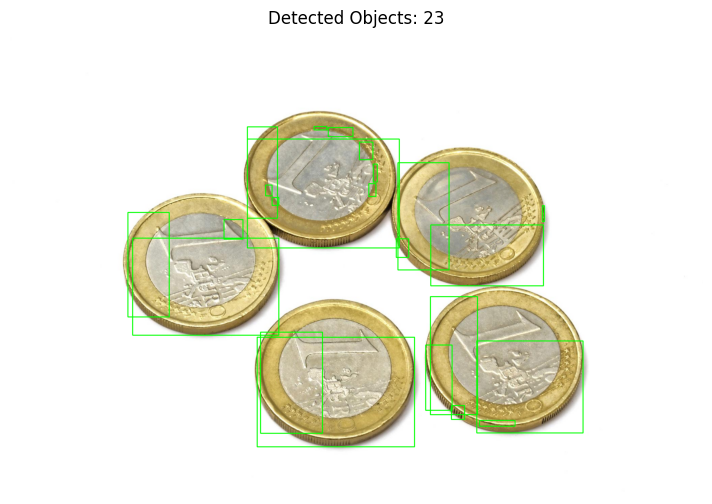

Total objects detected: 23


In [28]:
# Convert image to grayscale
gray = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)

# Reduce noise
blurred = cv2.GaussianBlur(gray, (5, 5), 0)

# Convert image to black and white
_, binary = cv2.threshold(
    blurred, 127, 255, cv2.THRESH_BINARY_INV
)

# Find object boundaries
contours, hierarchy = cv2.findContours(
    binary,
    cv2.RETR_EXTERNAL,
    cv2.CHAIN_APPROX_SIMPLE
)

# Copy original image
result = image.copy()

# Count valid objects
count = 0

for contour in contours:
    area = cv2.contourArea(contour)

    if area > 100:
        count += 1
        x, y, w, h = cv2.boundingRect(contour)

        cv2.rectangle(
            result,
            (x, y),
            (x + w, y + h),
            (0, 255, 0),
            2
        )

# Display result
plt.figure(figsize=(10, 6))
plt.imshow(result)
plt.title(f"Detected Objects: {count}")
plt.axis("off")
plt.show()

print("Total objects detected:", count)

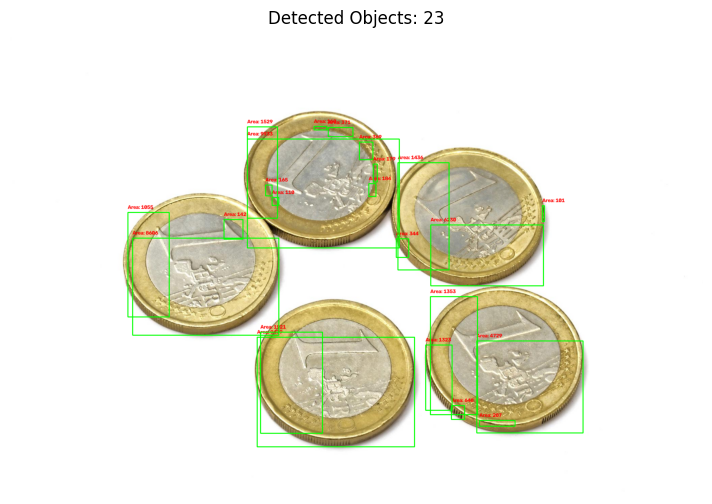

Total objects: 23


In [29]:

# Convert image to grayscale
gray = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)

# Reduce noise
blurred = cv2.GaussianBlur(gray, (5, 5), 0)

# Convert image to binary
_, binary = cv2.threshold(
    blurred, 127, 255, cv2.THRESH_BINARY_INV
)

# Find object boundaries
contours, _ = cv2.findContours(
    binary,
    cv2.RETR_EXTERNAL,
    cv2.CHAIN_APPROX_SIMPLE
)

# Copy original image
result = image.copy()

# Measure object areas
object_count = 0

for contour in contours:
    area = cv2.contourArea(contour)

    if area > 100:
        object_count += 1

        # Find object position
        x, y, w, h = cv2.boundingRect(contour)

        # Draw rectangle
        cv2.rectangle(
            result,
            (x, y),
            (x + w, y + h),
            (0, 255, 0),
            2
        )

        # Display area
        cv2.putText(
            result,
            f"Area: {int(area)}",
            (x, max(y - 10, 20)),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.5,
            (255, 0, 0),
            2
        )

# Display result
plt.figure(figsize=(10, 6))
plt.imshow(result)
plt.title(f"Detected Objects: {object_count}")
plt.axis("off")
plt.show()

print("Total objects:", object_count)
